In [4]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import tensorflow as tf 
from tensorflow import keras 
from tensorflow.keras import layers 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler 
import os 
import joblib 

# Crear carpetas de destino automáticas 
os.makedirs('../models', exist_ok=True) 
os.makedirs('../assets', exist_ok=True) 
print("TensorFlow instalado y listo en versión:", tf.__version__)

TensorFlow instalado y listo en versión: 2.22.0-rc1


In [8]:
np.random.seed(42) 
n_samples = 2000

ingresos = np.random.uniform(3000, 50000, n_samples) 
monto = np.random.uniform(1000, 30000, n_samples) 
plazo = np.random.choice([6, 12, 18, 24, 36, 48], n_samples) 
antiguedad = np.random.uniform(0.5, 15, n_samples) 
ratio_deuda = np.random.uniform(0.1, 0.85, n_samples) 
score_credito = np.random.randint(300, 850, n_samples) 

# Score sintético para definir riesgo 
score_riesgo = ( 
    (monto / (ingresos + 1e-5)) * 2.5 + 
    ratio_deuda * 3.0 - 
    (antiguedad / 15.0) * 1.5 - 
    ((score_credito - 300) / 550.0) * 2.5 + 
    np.random.normal(0, 0.5, n_samples) 
) 
riesgo_alto = (score_riesgo > 0.5).astype(int) 
    
df = pd.DataFrame({ 
        'ingresos_mensuales': ingresos, 
        'monto_solicitado': monto, 
        'plazo_meses': plazo, 
        'antiguedad_anos': antiguedad, 
        'ratio_endeudamiento': ratio_deuda, 
        'score_credito': score_credito, 
        'riesgo_alto': riesgo_alto 
}) 
print("Dataset creado exitosamente. Proporción de clases:") 
print(df['riesgo_alto'].value_counts(normalize=True))

Dataset creado exitosamente. Proporción de clases:
riesgo_alto
1    0.633
0    0.367
Name: proportion, dtype: float64


In [10]:
X = df.drop(columns=['riesgo_alto']) 
y = df['riesgo_alto'] 

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y) 
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp) 

scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train) 
X_val_scaled = scaler.transform(X_val) 
X_test_scaled = scaler.transform(X_test) 

joblib.dump(scaler, '../models/scaler_microcredito.pkl') 
print("Escalador guardado en ../models/scaler_microcredito.pkl")

Escalador guardado en ../models/scaler_microcredito.pkl


In [11]:
modelo_1 = keras.Sequential([ 
    layers.Dense(16, activation='relu', input_shape=(X_train_scaled.shape[1],)), 
    layers.Dense(8, activation='relu'), 
    layers.Dense(1, activation='sigmoid') 
], name="Modelo_Base") 
modelo_1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']) 
hist_1 = modelo_1.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=40, batch_size=32, verbose=0) 

modelo_2 = keras.Sequential([ 
    layers.Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)), 
    layers.BatchNormalization(), 
    layers.Dropout(0.3), 
    layers.Dense(16, activation='relu'), 
    layers.Dropout(0.2), 
    layers.Dense(1, activation='sigmoid') 
], name="Modelo_Mejorado") 

modelo_2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']) 
hist_2 = modelo_2.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=40, batch_size=32, verbose=0) 

modelo_2.save('../models/modelo_microcredito.keras') 
print("Modelo guardado exitosamente en ../models/modelo_microcredito.keras")

c:\Users\dany1\microcredito-pyme-agent\venv\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modelo guardado exitosamente en ../models/modelo_microcredito.keras


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


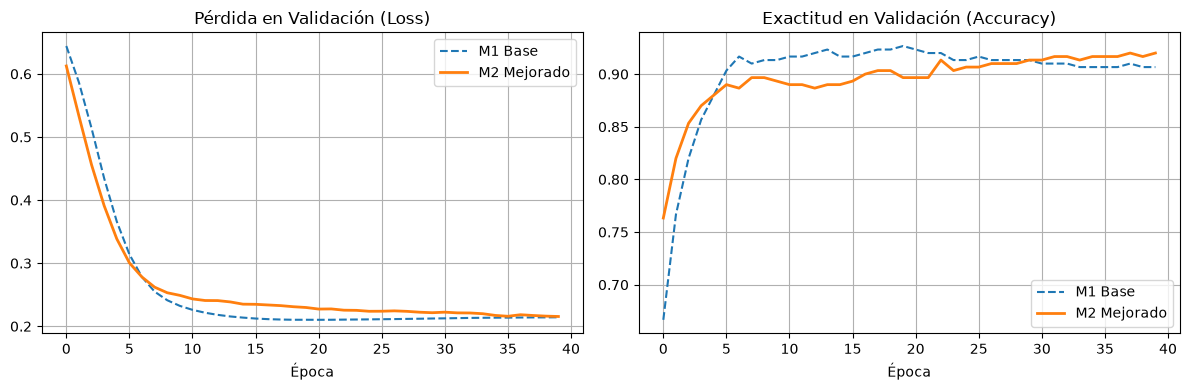

Gráfica guardada en ../assets/curvas_entrenamiento_u4.png
\n================ EVIDENCIA DE FALLO REAL ================
Total de fallos en el conjunto de prueba: 33 de 300
Ejemplo de un caso donde la red se equivocó:
ingresos_mensuales     18198.463419
monto_solicitado       17555.445088
plazo_meses               48.000000
antiguedad_anos            2.804409
ratio_endeudamiento        0.180476
score_credito            825.000000
valor_real                 1.000000
prediccion                 0.000000
probabilidad_riesgo        0.313377
Name: 1601, dtype: float64


In [12]:
probs_test = modelo_2.predict(X_test_scaled).flatten() 
preds_test = (probs_test > 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4)) 
axes[0].plot(hist_1.history['val_loss'], '--', label='M1 Base') 
axes[0].plot(hist_2.history['val_loss'], label='M2 Mejorado', linewidth=2) 
axes[0].set_title('Pérdida en Validación (Loss)') 
axes[0].set_xlabel('Época') 
axes[0].legend() 
axes[0].grid(True) 

axes[1].plot(hist_1.history['val_accuracy'], '--', label='M1 Base') 
axes[1].plot(hist_2.history['val_accuracy'], label='M2 Mejorado', linewidth=2) 
axes[1].set_title('Exactitud en Validación (Accuracy)') 
axes[1].set_xlabel('Época') 
axes[1].legend() 
axes[1].grid(True) 

plt.tight_layout() 
plt.savefig('../assets/curvas_entrenamiento_u4.png', dpi=300) 
plt.show() 
print("Gráfica guardada en ../assets/curvas_entrenamiento_u4.png")

df_test = X_test.copy() 
df_test['valor_real'] = y_test.values 
df_test['prediccion'] = preds_test 
df_test['probabilidad_riesgo'] = probs_test 
fallos = df_test[df_test['valor_real'] != df_test['prediccion']]
 
print(f"\\n================ EVIDENCIA DE FALLO REAL ================") 
print(f"Total de fallos en el conjunto de prueba: {len(fallos)} de {len(y_test)}") 
print("Ejemplo de un caso donde la red se equivocó:") 
print(fallos.iloc[0])